# 02. KOTE 탐색적 분석 + 대응표 적용

KOTE(한국어 온라인 댓글 5만 건, 44개 원본 라벨)를 살펴보고, 대응표로 44개 **KOTE 원본 라벨**을 8개 **감정 범주**로 묶은 학습용 데이터를 만든다.

- 데이터: [searle-j/KOTE](https://github.com/searle-j/KOTE), 논문 Jeon et al. (2022) *User Guide for KOTE*
- 출처: 12개 플랫폼(뉴스, 커뮤니티, SNS, 쇼핑, 영상, **영화 리뷰**, 마이크로블로그, 포럼)에서 사이트별로 균형 있게 샘플링 (논문 §4.1)
- GPU 불필요

In [1]:
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !apt-get -qq install fonts-nanum > /dev/null

In [2]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 그래프 한글 표시
if IN_COLAB:
    font_manager.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
    plt.rcParams["font.family"] = "NanumGothic"
elif sys.platform == "darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

BLUE, GRAY = "#2a78d6", "#a9a8a2"

def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRAY)
    ax.tick_params(colors="#52514e")
    ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)

Matplotlib is building the font cache; this may take a moment.


## 1. 설정

In [3]:
MIN_VOTES = 2  # 평가자 5명 중 이 수 이상이 고른 원본 라벨만 정답으로 인정

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/miniproject/kote-8cat"
else:
    OUTPUT_DIR = "outputs/kote-8cat"

## 2. 데이터 불러오기

KOTE는 두 형태로 배포된다.

- `raw.json`: 댓글마다 평가자 5명이 각각 고른 원본 라벨 목록
- `train/val/test.tsv` (`dichotomized`): 표를 0/1로 바꾼 라벨과 학습/검증/테스트 분할

정답은 `raw.json`에서 직접 만들고, 분할만 TSV의 ID를 따른다.

In [4]:
import json
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd

KOTE_LABELS = [
    "불평/불만", "환영/호의", "감동/감탄", "지긋지긋", "고마움", "슬픔", "화남/분노", "존경", "기대감",
    "우쭐댐/무시함", "안타까움/실망", "비장함", "의심/불신", "뿌듯함", "편안/쾌적", "신기함/관심", "아껴주는",
    "부끄러움", "공포/무서움", "절망", "한심함", "역겨움/징그러움", "짜증", "어이없음", "없음", "패배/자기혐오",
    "귀찮음", "힘듦/지침", "즐거움/신남", "깨달음", "죄책감", "증오/혐오", "흐뭇함(귀여움/예쁨)", "당황/난처",
    "경악", "부담/안_내킴", "서러움", "재미없음", "불쌍함/연민", "놀람", "행복", "불안/걱정", "기쁨", "안심/신뢰",
]  # dichotomized TSV의 라벨 인덱스 순서

def load_split(split):
    url = f"https://raw.githubusercontent.com/searle-j/KOTE/main/{split}.tsv"
    df = pd.read_csv(url, sep="\t", header=None, names=["id", "text", "dichotomized"], quoting=3, dtype={"id": str})
    df["dichotomized"] = df["dichotomized"].map(lambda s: [KOTE_LABELS[int(i)] for i in str(s).split(",")])
    return df

splits = {name: load_split(name) for name in ["train", "val", "test"]}

with urllib.request.urlopen("https://huggingface.co/datasets/searle-j/kote/resolve/main/raw.json") as f:
    raw = json.load(f)

# 댓글별 원본 라벨 득표수 (0–5)
votes = {cid: Counter(label for picks in item["labels"].values() for label in picks) for cid, item in raw.items()}
for df in splits.values():
    df["votes"] = df["id"].map(votes)

print({name: len(df) for name, df in splits.items()})
assert all(df["votes"].notna().all() for df in splits.values())
splits["train"].head(3)

{'train': 40000, 'val': 5000, 'test': 5000}


,id,text,dichotomized,votes
0,39087,내가 톰행크스를 좋아하긴 했나보다... 초기 영화 빼고는 다 봤네.,"[감동/감탄, 뿌듯함, 신기함/관심, 아껴주는, 깨달음, 놀람]","{'깨달음': 4, '신기함/관심': 3, '놀람': 3, '감동/감탄': 2, '..."
1,30893,"정말 상상을 초월하는 무개념 진상들 상대하다 우울증, 공항장애 걸리는 공무원 많아요...","[불평/불만, 슬픔, 존경, 안타까움/실망, 절망, 짜증, 깨달음, 부담/안_내킴,...","{'불평/불만': 1, '슬픔': 4, '짜증': 1, '절망': 1, '서러움':..."
2,45278,"새로운 세상과 조우한 자의 어린아이 같은 반응, 어쩌면 회복된 것은 눈이 아닌 순수...","[환영/호의, 감동/감탄, 존경]","{'감동/감탄': 3, '환영/호의': 2, '존경': 5, '깨달음': 1, '고..."


## 3. 정답 기준 정하기: `dichotomized` vs 득표수

`dichotomized`는 댓글마다 득표수를 min-max 정규화한 뒤 0.2를 넘으면 1로 만든다 (논문 §4.4).
표가 적게 몰린 댓글에서는 **평가자 1명만 고른 라벨도 정답**이 된다. 예시:

In [5]:
ex = splits["train"].iloc[0]
print(ex["text"])
print("득표수      :", dict(ex["votes"].most_common()))
print("dichotomized:", ex["dichotomized"])

내가 톰행크스를 좋아하긴 했나보다... 초기 영화 빼고는 다 봤네.
득표수      : {'깨달음': 4, '신기함/관심': 3, '놀람': 3, '감동/감탄': 2, '아껴주는': 1, '뿌듯함': 1}
dichotomized: ['감동/감탄', '뿌듯함', '신기함/관심', '아껴주는', '깨달음', '놀람']


## 4. 대응표

In [6]:
CATEGORY_MAPPING = {
    "기쁨": ["환영/호의", "감동/감탄", "고마움", "즐거움/신남", "행복", "기쁨", "흐뭇함(귀여움/예쁨)", "뿌듯함", "편안/쾌적", "안심/신뢰"],
    "슬픔": ["슬픔", "안타까움/실망", "절망", "서러움", "불쌍함/연민", "패배/자기혐오", "힘듦/지침"],
    "분노": ["화남/분노", "불평/불만", "짜증", "지긋지긋", "어이없음"],
    "공포": ["공포/무서움", "불안/걱정"],
    "놀람": ["놀람", "경악", "신기함/관심", "당황/난처"],
    "혐오": ["증오/혐오", "역겨움/징그러움", "한심함", "우쭐댐/무시함"],
    "지루함": ["재미없음"],
    "중립": ["없음"],
}
EXCLUDED_LABELS = ["존경", "기대감", "비장함", "의심/불신", "아껴주는", "부끄러움", "귀찮음", "깨달음", "죄책감", "부담/안_내킴"]

CATEGORIES = list(CATEGORY_MAPPING)
SOURCE_TO_CATEGORY = {src: cat for cat, srcs in CATEGORY_MAPPING.items() for src in srcs}

# 44개 원본 라벨이 빠짐없이, 한 번씩만 배정되었는지 확인
assigned = list(SOURCE_TO_CATEGORY) + EXCLUDED_LABELS
assert sorted(assigned) == sorted(KOTE_LABELS), set(KOTE_LABELS) ^ set(assigned)
assert len(assigned) == len(set(assigned)) == 44

pd.DataFrame(
    [(cat, len(srcs), ", ".join(srcs)) for cat, srcs in CATEGORY_MAPPING.items()]
    + [("(제외 라벨)", len(EXCLUDED_LABELS), ", ".join(EXCLUDED_LABELS))],
    columns=["감정 범주", "원본 라벨 수", "KOTE 원본 라벨"],
)

,감정 범주,원본 라벨 수,KOTE 원본 라벨
0,기쁨,10,"환영/호의, 감동/감탄, 고마움, 즐거움/신남, 행복, 기쁨, 흐뭇함(귀여움/예쁨)..."
1,슬픔,7,"슬픔, 안타까움/실망, 절망, 서러움, 불쌍함/연민, 패배/자기혐오, 힘듦/지침"
2,분노,5,"화남/분노, 불평/불만, 짜증, 지긋지긋, 어이없음"
3,공포,2,"공포/무서움, 불안/걱정"
4,놀람,4,"놀람, 경악, 신기함/관심, 당황/난처"
5,혐오,4,"증오/혐오, 역겨움/징그러움, 한심함, 우쭐댐/무시함"
6,지루함,1,재미없음
7,중립,1,없음
8,(제외 라벨),10,"존경, 기대감, 비장함, 의심/불신, 아껴주는, 부끄러움, 귀찮음, 깨달음, 죄책감..."


## 5. 원본 라벨 → 감정 범주 변환 규칙

1. 원본 라벨은 `MIN_VOTES`명 이상이 고른 것만 인정한다.
2. 감정 범주는 거기 매핑된 원본 라벨 중 하나라도 있으면 해당한다 (OR).
3. **중립**은 다른 범주가 하나도 없을 때만 남긴다.
4. 남은 범주가 없으면(제외 라벨만 있으면) `None` → 학습에서 뺀다.

In [7]:
def to_categories(source_labels):
    """원본 라벨 목록 → 감정 범주 집합. 학습에서 뺄 댓글이면 None."""
    cats = {SOURCE_TO_CATEGORY[s] for s in source_labels if s in SOURCE_TO_CATEGORY}
    if len(cats) > 1:
        cats.discard("중립")
    return cats or None

def accepted_labels(vote_counter, min_votes=MIN_VOTES):
    return [label for label, n in vote_counter.items() if n >= min_votes]

assert to_categories(["짜증", "어이없음"]) == {"분노"}
assert to_categories(["재미없음", "안타까움/실망"]) == {"지루함", "슬픔"}
assert to_categories(["없음"]) == {"중립"}
assert to_categories(["없음", "기쁨"]) == {"기쁨"}       # 중립은 다른 범주와 같이 붙지 않음
assert to_categories(["없음", "깨달음"]) == {"중립"}     # 제외 라벨은 무시
assert to_categories(["깨달음", "존경"]) is None         # 제외 라벨만 → 학습에서 뺌
assert to_categories([]) is None
assert accepted_labels(Counter({"놀람": 3, "뿌듯함": 1})) == ["놀람"]
print("변환 규칙 확인 완료")

변환 규칙 확인 완료


### 정답 기준별 비교 (train)

In [8]:
def summarize(label_lists):
    cats = [to_categories(labels) for labels in label_lists]
    kept = [c for c in cats if c is not None]
    k = np.array([len(c) for c in kept])
    row = {
        "원본 라벨/댓글": np.mean([len(l) for l in label_lists]),
        "범주/댓글": k.mean(),
        "4범주 이상": (k >= 4).mean(),
        "제외되는 댓글": 1 - len(kept) / len(cats),
    }
    row.update({cat: np.mean([cat in c for c in kept]) for cat in CATEGORIES})
    return row

train = splits["train"]
comparison = pd.DataFrame({
    "dichotomized": summarize(train["dichotomized"]),
    "2명 이상": summarize(train["votes"].map(lambda v: accepted_labels(v, 2))),
    "3명 이상": summarize(train["votes"].map(lambda v: accepted_labels(v, 3))),
}).T
comparison.style.format("{:.1%}").format("{:.2f}", subset=["원본 라벨/댓글", "범주/댓글"])

,원본 라벨/댓글,범주/댓글,4범주 이상,제외되는 댓글,기쁨,슬픔,분노,공포,놀람,혐오,지루함,중립
dichotomized,7.91,2.90,33.2%,0.2%,49.8%,53.2%,57.6%,20.0%,57.1%,42.6%,9.2%,0.5%
2명 이상,4.10,1.94,6.4%,3.3%,38.6%,35.3%,45.4%,8.9%,32.0%,26.4%,4.8%,3.1%
3명 이상,2.06,1.45,0.9%,20.9%,35.1%,24.5%,41.0%,4.8%,17.5%,16.4%,3.7%,2.5%


`dichotomized`로는 댓글 하나에 평균 3개 범주가 켜지고 기쁨·슬픔이 절반 넘는 댓글에 동시에 붙어 정답으로 쓰기 어렵다.
3명 이상은 깔끔하지만 댓글의 약 1/5을 잃는다. → **2명 이상**을 정답 기준으로 쓴다.

## 6. 변환 적용

In [9]:
def build(df):
    cats = df["votes"].map(lambda v: to_categories(accepted_labels(v)))
    out = df.loc[cats.notna(), ["id", "text"]].reset_index(drop=True)
    for cat in CATEGORIES:
        out[cat] = cats.dropna().map(lambda c: int(cat in c)).values
    return out

data = {name: build(df) for name, df in splits.items()}

pd.DataFrame({
    name: {
        "원본 댓글": len(splits[name]),
        "사용 댓글": len(data[name]),
        "제외 비율": f"{1 - len(data[name]) / len(splits[name]):.1%}",
        "범주/댓글": f"{data[name][CATEGORIES].sum(axis=1).mean():.2f}",
    }
    for name in data
}).T

,원본 댓글,사용 댓글,제외 비율,범주/댓글
train,40000,38687,3.3%,1.94
val,5000,4835,3.3%,1.95
test,5000,4844,3.1%,1.94


In [10]:
freq = pd.DataFrame({name: d[CATEGORIES].mean() for name, d in data.items()})
freq.style.format("{:.1%}")

,train,val,test
기쁨,38.6%,37.4%,37.4%
슬픔,35.3%,36.5%,35.3%
분노,45.4%,46.7%,46.1%
공포,8.9%,8.3%,9.1%
놀람,32.0%,31.9%,32.3%
혐오,26.4%,27.1%,26.3%
지루함,4.8%,4.9%,4.8%
중립,3.1%,2.6%,3.0%


## 7. 그래프

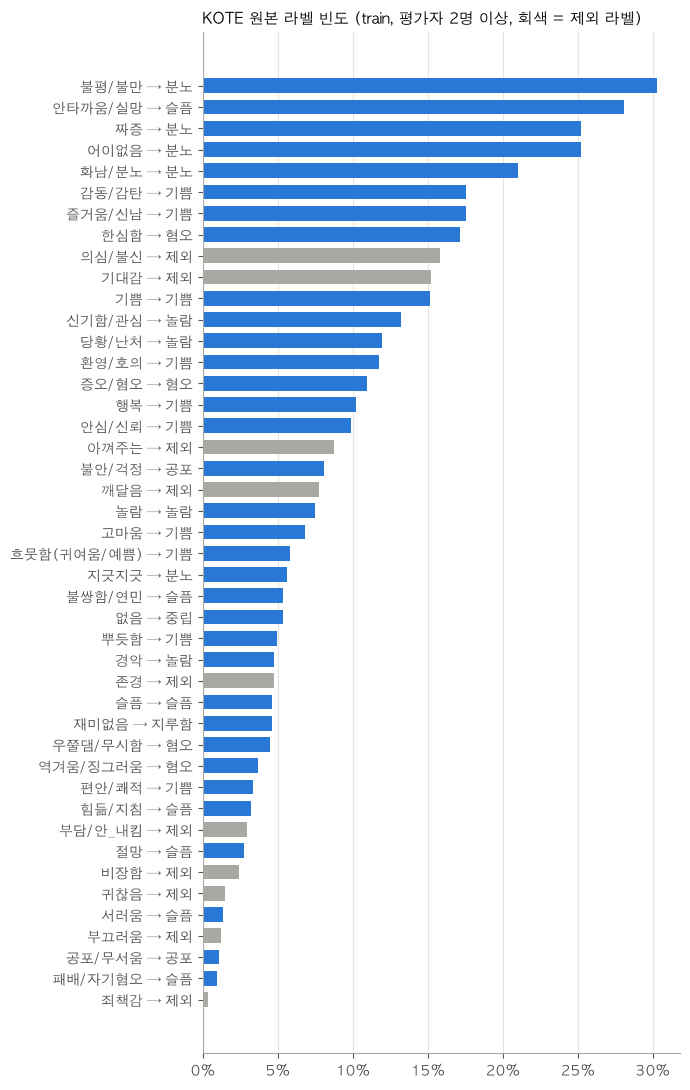

In [11]:
# 원본 라벨 빈도 (2명 이상 기준, train)
label_freq = pd.Series(Counter(l for v in train["votes"] for l in accepted_labels(v))).reindex(KOTE_LABELS, fill_value=0)
label_freq = (label_freq / len(train)).sort_values()

fig, ax = plt.subplots(figsize=(7, 11))
colors = [GRAY if l in EXCLUDED_LABELS else BLUE for l in label_freq.index]
names = [f"{l} → {SOURCE_TO_CATEGORY.get(l, '제외')}" for l in label_freq.index]
ax.barh(names, label_freq.values, color=colors, height=0.7)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("KOTE 원본 라벨 빈도 (train, 평가자 2명 이상, 회색 = 제외 라벨)", loc="left", fontsize=11)
tidy(ax)
plt.tight_layout()
plt.show()

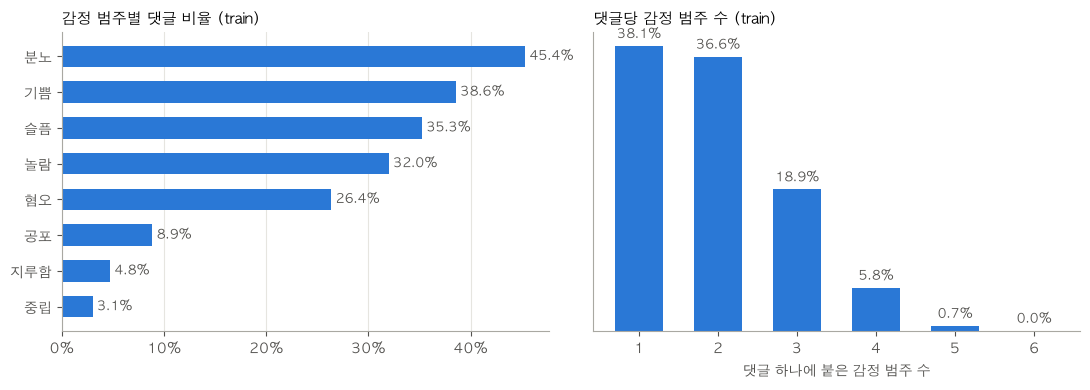

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

f = data["train"][CATEGORIES].mean().sort_values()
bars = ax1.barh(f.index, f.values, color=BLUE, height=0.6)
ax1.bar_label(bars, labels=[f"{v:.1%}" for v in f.values], padding=3, color="#52514e", fontsize=9)
ax1.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax1.set_title("감정 범주별 댓글 비율 (train)", loc="left", fontsize=11)
tidy(ax1)

k = data["train"][CATEGORIES].sum(axis=1).value_counts(normalize=True).sort_index()
bars = ax2.bar(k.index.astype(str), k.values, color=BLUE, width=0.6)
ax2.bar_label(bars, labels=[f"{v:.1%}" for v in k.values], padding=3, color="#52514e", fontsize=9)
ax2.set_yticks([])
ax2.set_xlabel("댓글 하나에 붙은 감정 범주 수", color="#52514e")
ax2.set_title("댓글당 감정 범주 수 (train)", loc="left", fontsize=11)
tidy(ax2)
ax2.grid(False)

plt.tight_layout()
plt.show()

## 8. 범주별 예시 (범주가 하나만 붙은 댓글)

In [13]:
single = data["train"][data["train"][CATEGORIES].sum(axis=1) == 1]
for cat in CATEGORIES:
    print(f"[{cat}]")
    for text in single[single[cat] == 1]["text"].sample(3, random_state=0):
        print("  -", text[:80])

[기쁨]
  - 만족해요 배송도빠르고~ 11번가 여자친구때문에알게되서 이용한게벌써 이렇게 오래됐네요.. 지금은 여자친구가 개인사생활(사정상) 제가대신 쇼핑도해주
  - ㅋㅋㅋㅋㅋㅋㅋ챙겨?
  - 당신으로 인해 행복했습니다. 감사합니다
[슬픔]
  - 와 첫번째사진이 넙대하고 길다고?? 내얼굴보다 넓은사람 있을까?ㅠㅡ나같은사람도 그냥살고있는데.. 행복한고민이라참부럽네..ㅜ
  - 저 동생역할 오빠 없나봐
  - 어느날 문득 걸음을 멈추고 뒤돌아서서, 언젠가의 그 시간을 되돌아 볼 때 내가 그에게 후회는 아니었으면 좋겠다고  아픔이거나 슬픔이거나 갈증이거
[분노]
  - 근데 현재 우리와 일본 입장이 바뀐상태였다면 분명히 일본 저것들이 선빨 불참선언 했을것이다
  - 임산부석 배려는 의무가 아닌디
  - 평소보다 잠을 푹 잤더니 확실히 눈의 피곤이 덜하다. 근데 꿈에서 공군 에이스 아이들은 왜 나왔니. 말라서 초췌한 구현이가 나왔다. 아마 병장이
[공포]
  - 조심해라.. 무청이 저거 스토킹만하는게 아니라 납치 감금까지 한다.. 2
  - 이론..몸조리 잘하시구요...형님.ㅜㅜ
  - 여기 믿을만한 사이트인가요? 프리오더스만 있는줄 알았거든요..
[놀람]
  - 이틀째써봤눈데.낮에눈 편하게 자는거같슨데.밤에눈 내려와서 베개밖에서 자고있더라고요.구래서 낮에만사용해요.아직 50 일도 인됐눈데.더 크면 안내려
  - 통계학자에 똑똑하고 배경좋고 기쎄고.. 아무도 못건드릴듯 존멋
  -  어린 병건이는 불법복제의 악영향을 걱정했지만, 정작 성인이 된 병건이의 만화는 불법복제를 저지르는 밤토끼로부터 자유로웠다....
[혐오]
  - 근데 일본은 수익성은 큰데 실력이.... 그래서 일본 연무덬들이 한국 많이 옴
  - 덩치가 있는 남자라. 난 그러면 안비키냐는 식으로 문 막고 쳐다보는데. ㅋㅋ 그럼 알아서 비킴 ㅋㅋㅋㅋㅋ
  - 공무원이 항명을 했다면 사표를 써야지.  좋은 일이다. 쓰레기 분리 배출의 날!!!
[지루함]
  - 할게없음........
  - 막연하고 모호

## 9. 저장

In [14]:
import os

os.makedirs(OUTPUT_DIR, exist_ok=True)
for name, d in data.items():
    d.to_csv(f"{OUTPUT_DIR}/{name}.csv", index=False)
print(os.listdir(OUTPUT_DIR), f"감정 범주 열: {CATEGORIES}")

['val.csv', 'test.csv', 'train.csv'] 감정 범주 열: ['기쁨', '슬픔', '분노', '공포', '놀람', '혐오', '지루함', '중립']
